# Double-Bracket Algorithmic Cooling (DBAC)

Code accompanying [*Double-Bracket Algorithmic Cooling*](https://arxiv.org/abs/2510.00302)
(M. Alghadeer, K. U. Giang, S. Cao, S. D. Fasciati, M. Piscitelli, N. Ng, P. J. Leek,
M. Gluza, M. Bakr). This page walks through the paper's main experimental result (its Fig. 4):
**how much a single qubit is cooled by DBAC as we spend more qubits as resources**, compared with
data taken on a superconducting-qubit device.

The `dbac` package provides the DME implementations, the DB-QITE/GCI recursion, the HBAC
baseline and all the plotting code used for the paper figures. See [Installation](installation.md)
to set it up, the [Quick start](quickstart.md) for a first example, the
[guide](guide/conventions.md) for how each part works, and the [API reference](api/index.md)
for every function.

## Background: cooling a qubit by removing its coherence

*Algorithmic cooling* (AC) lowers the entropy of one qubit by moving entropy into other qubits
using only unitary operations. DBAC solves a complementary problem. The qubits carry **no
entropy**: every one of them is prepared in the same *pure* state $|\psi\rangle$, but we do not
know which state it is, and we cannot measure it without collapsing the superposition. The goal is
still to rotate one qubit to the ground state $|0\rangle$, that is, to remove its **quantum
coherence**.

Learning $|\psi\rangle$ first (tomography) does not escape the problem: the statistical error
only falls as $1/\sqrt{n}$ in the number of copies $n$. DBAC instead uses the other copies of
$|\psi\rangle$ directly as **quantum instructions**: they act as a temporary Hamiltonian that
tells the target qubit which way to rotate, with no measurement and no feedback. The circuit
itself is the same for every input state, and the state it meets decides what it does.

As in Nernst's unattainability principle, perfect cooling would need infinitely many
instructions. With a finite number of qubits the cooling is partial, and it improves as more
qubits are added. This page shows that trade-off.

## How DBAC works

**Imaginary-time evolution.** Evolving in imaginary time under a Hamiltonian $\hat H$,

$$
|\psi(\tau)\rangle = \frac{e^{-\tau \hat H}|\psi\rangle}{\lVert e^{-\tau \hat H}|\psi\rangle\rVert},
$$

maps any pure state to another pure state that gets closer to the ground state of $\hat H$ as
$\tau$ grows, unless the input is an exact excited eigenstate. DBAC uses $\hat H = -Z$, so the
ground state is $|0\rangle$ with energy $-1$ and the excited state is $|1\rangle$ with energy $+1$.
The energy of the data qubit is $E = \langle\psi|\hat H|\psi\rangle$.

**One DBAC step.** Imaginary-time evolution is not unitary, but for a single qubit it can be
approximated by a *double-bracket* step built from the group commutator. A reflection about the
state itself, $e^{it|\psi\rangle\langle\psi|}$, is sandwiched between two rotations about $\hat H$:

$$
|\psi_\mathrm{DBAC}\rangle = e^{it\hat H}\, e^{it|\psi\rangle\langle\psi|}\, e^{-it\hat H}\,|\psi\rangle .
$$

When the reflection is applied exactly, the energy after one step with duration $t$, starting
from energy $E_0$, is known in closed form (Eq. 3 of the paper):

$$
E_\mathrm{DBAC} = E_0 - 2\sin^2(t)\,(1-E_0^2)\,\Big[(1-\cos t)\,E_0 + \cos t\Big].
$$

The correction vanishes for $E_0=\pm1$. The two poles $|0\rangle$ and $|1\rangle$ are therefore fixed
points: $|0\rangle$ is already cold, and $|1\rangle$ is an excited eigenstate that the flow cannot
move. Every other state is cooled.

**Density-matrix exponentiation (DME).** The reflection $e^{it|\psi\rangle\langle\psi|}$ would
need to know $|\psi\rangle$. DME avoids this by using a copy of the state as the Hamiltonian. For
a small duration $t$, a partial SWAP between a data qubit $\sigma$ and an instruction qubit $\rho$ gives

$$
\mathrm{Tr}_2\!\left[e^{-it\,\mathrm{SWAP}}(\sigma\otimes\rho)\,e^{it\,\mathrm{SWAP}}\right]
= \sigma - it[\rho,\sigma] + O(t^2) \approx e^{-it\rho}\,\sigma\, e^{it\rho}.
$$

The partial SWAP $U_\mathrm{DME}(\varphi)=e^{i\varphi\,\mathrm{SWAP}}$ is the same circuit for every $\rho$, so
the information in $\rho$ decides which rotation is applied. On hardware it is compiled from the
Heisenberg interaction $XX+YY+ZZ$ using the native $ZZ$ interaction of the transmons
($U_\mathrm{DME}(\varphi) = R_{ZZ}(\varphi)\,R_{YY}(\varphi)\,R_{XX}(\varphi)$).

**Two knobs: $M$ and $k$.** Using one copy per DME call only approximates the exponential. Two
independent resources then control how well DBAC cools:

| symbol | meaning | what it costs |
|---|---|---|
| $M$ | number of **DME steps** (Trotter steps) inside one DBAC step. The duration $t$ is split into $M$ pieces $t/M$, each using a fresh copy of the instruction state, and the error of the approximation shrinks as $O(t^2/M)$. | $M$ copies of $|\psi\rangle$ per DBAC step |
| $k$ | number of **DBAC steps**, applied recursively. Step $k+1$ uses the *cooled* output of step $k$ as its instruction, so each step starts from a colder state. | the instructions of step $k$ must be prepared first, in parallel, so the copies multiply |

More of either resource means more qubits $n$ in the circuit and lower energy of the data qubit.

## The experiment

Every circuit is run as follows.

1. **Prepare.** All $n$ qubits start in $|0\rangle$ and receive the same rotation
   $R_X(\theta)$, so each holds $|\psi(\theta)\rangle = R_X(\theta)|0\rangle$. In the paper's
   convention $R_X(\theta)=e^{-i\theta X}$, so $\theta=0$ is the ground state $|0\rangle$, the
   energy rises as $\theta$ grows, and $\theta=\pi/2$ is the excited state $|1\rangle$.
   The energy of the untouched state is $E_0(\theta) = -\cos 2\theta$.
2. **Apply DBAC** with $k$ DBAC steps and $M$ DME steps each. On the instruction qubits,
   $R_Z(\pi/4) = e^{-it\hat H}$ with $t=\pi/4$ prepares $e^{-it\hat H}|\psi\rangle$. The data
   qubit then interacts with the instructions through $U_\mathrm{DME}$. The final rotation
   $e^{it\hat H}$ on the data qubit is a $Z$ rotation and does not change its energy, so it is
   left out of the hardware circuits.
3. **Read out** the energy of the data qubit and repeat for a sweep of $\theta$.

Without DBAC the energy follows the *Initial state* curve $-\cos 2\theta$. After DBAC it should move
toward the ground-state value $-1$.

The three circuits below are the ones run on the device. Dashed lines separate the DBAC steps.

| circuit | $k$ (DBAC steps) | $M$ (DME steps) | qubits $n$ | instruction copies |
|---|---|---|---|---|
| A | 1 | 1 | 2 | 1 |
| B | 1 | 2 | 3 | 2 |
| C | 2 | 1 | 4 | 3 |

The code that generates the circuits' energy curves, the digitized experimental data and the
plot styling is in [`scripts/figure_4.py`](https://github.com/khanhuyengiang/dbac/blob/main/scripts/figure_4.py),
and the plotting code is in [`src/dbac/plotting/`](https://github.com/khanhuyengiang/dbac/tree/main/src/dbac/plotting).

In [1]:
%matplotlib inline
import sys
sys.path.append('..')
sys.path.append('../src')
sys.path.append('../notebooks')  # for config.py

import numpy as np

from config import plot_path
from dbac.plotting import use_paper_style, figure_size, plot_single_energy_curve, draw_dbac_circuit
from scripts.figure_4 import (
    CIRCUIT_COLORS, CIRCUIT_FILENAMES, CIRCUIT_MARKERS, EXPERIMENTAL_ENERGY,
    OPTIMAL_S_PATH, XTICKS, XTICK_LABELS, run_dbac_circuits,
)
from dbac.gci import GCI
from dbac.dbqite import initial_psi
from dbac.utils import rx_sweep

use_paper_style(font_size=10, figsize=figure_size("PRD", "onecol"))

[Qibo 0.3.6|INFO|2026-10-26 14:05:21]: Using numpy backend on /CPU:0


### Simulating DBAC

For each $\theta$ we build $|\psi(\theta)\rangle = R_X(\theta)|0\rangle$ and run DB-QITE with the
step durations optimized for each $(M, k)$ (cached in `optimal_s_Mk.npy`). The result is the
analytical curve of each circuit, from noiseless simulation with $M$-step Trotterized DME. The
*Initial state* baseline is the energy of $|\psi(\theta)\rangle$ before any cooling.

In [2]:
optimal_s_Mk = np.load(OPTIMAL_S_PATH)
thetas = np.linspace(0, 1, 100)

psis_energy = rx_sweep(thetas, start=np.array([[1], [0]], dtype=complex))
theta_angles = thetas * np.pi / 2
res_init = [GCI(initial_psi, psi, 1, np.linspace(0.01, 1, 2)).execute_gci()[0][-1] for psi in psis_energy]
energy_results = run_dbac_circuits(psis_energy, optimal_s_Mk, as_fidelity=False)

def plot_circuit_energy(label):
    plot_single_energy_curve(
        theta_angles, res_init, label, energy_results[label],
        CIRCUIT_COLORS[label], CIRCUIT_MARKERS[label],
        experimental=EXPERIMENTAL_ENERGY.get(label),
        xticks=XTICKS, xtick_labels=XTICK_LABELS, show=True,
        save_path=plot_path(CIRCUIT_FILENAMES[label]))

## Each circuit individually, overlaid with hardware experiment data

In each plot below, the horizontal axis is the initialization angle $\theta$ and the vertical
axis is the energy of the data qubit after the circuit.

- the **dotted** curve is the *Initial state*, the energy $-\cos 2\theta$ with no cooling;
- the **solid** curve is the *Analytical* prediction of DBAC for that circuit;
- the **open circles** are the *Experiment*, measured on the superconducting device.

Cooling shows up as a curve **below** the dotted one, closer to the ground-state energy $-1$.
Both ends are fixed points, as discussed above: $|0\rangle\langle 0|$ at $\theta=0$ is already in the
ground state, and $|1\rangle\langle 1|$ at $\theta=\pi/2$ is an exact excited eigenstate that
imaginary-time evolution cannot move.

### Circuit A: 1 DBAC step, 1 DME step ($n=2$)

The minimal DBAC circuit. One instruction qubit is rotated by $R_Z(\pi/4)$ and the data qubit
$q_1$ is coupled to it through a single $U_\mathrm{DME}(\pi/4)$. The step duration
$t=\pi/4$ cools a wide range of initial states.

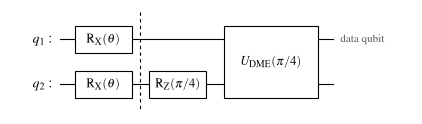

In [3]:
draw_dbac_circuit("A");

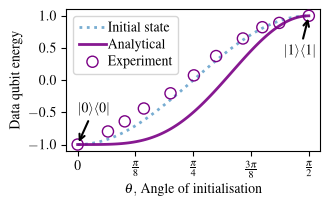

In [4]:
plot_circuit_energy(r'$n=2$');

A single instruction already lowers the energy of the data qubit across the sweep. The
experimental points lie between the analytical curve and the uncooled baseline: the cooling is
real but smaller than in the noiseless simulation, because of gate errors and decoherence. Since
$M=1$, the DME step is also a single, coarse partial SWAP.

### Circuit B: 1 DBAC step, 2 DME steps ($n=3$)

The same total duration $t=\pi/4$ is now split into $M=2$ DME steps of $\pi/8$ each. Each step
uses its own instruction copy ($q_1$ and $q_3$, both rotated by $R_Z(\pi/4)$), and both act on the
data qubit $q_2$. This distributes the DME over two instruction qubits, a finer Trotterization of
$e^{-it\rho}$ than circuit A, at the price of one more qubit.

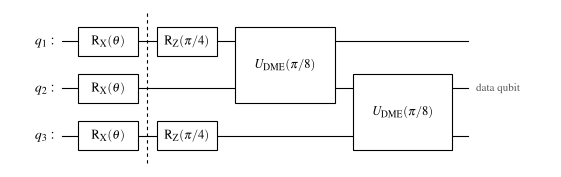

In [5]:
draw_dbac_circuit("B");

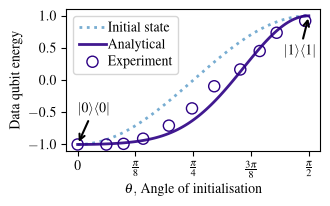

In [6]:
plot_circuit_energy(r'$n=3$');

Cooling is stronger than in circuit A: the curve is flatter and sits lower, and the experimental
data confirm this. Of the three circuits, this one agrees best with the analytical prediction.
The extra instruction qubit improves the DME approximation, which shows that distributing DME
improves cooling.

### Circuit C: 2 DBAC steps, 1 DME step ($n=4$)

Here the DBAC recursion is applied twice ($k=2$) with a single DME step in each. The first step is
circuit A, run twice in parallel: once to cool the data qubit $q_2$ (instruction $q_1$) and once to
prepare a cooled copy on $q_3$ (instruction $q_4$). The second step, after the second dashed line,
uses that cooled copy on $q_3$ as the instruction for $q_2$, so it starts from a colder state than
a single step could provide.

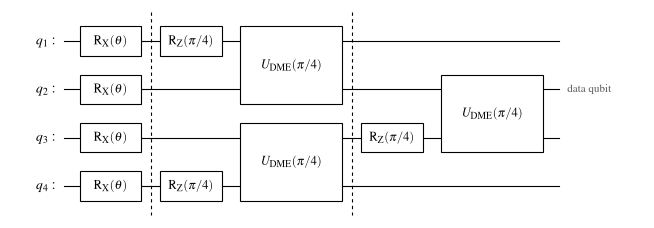

In [7]:
draw_dbac_circuit("C");

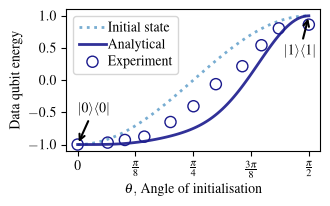

In [8]:
plot_circuit_energy(r'$n=4$');

In the noiseless simulation, the two recursion steps cool even more than circuit B. On the device,
however, this circuit is the deepest and has the most entangling gates, and the siZZle pulses that
implement them are relatively long. Decoherence accumulates, so the experimental points lie well above the analytical curve and
only modestly below the uncooled state. Circuit C is at the verge of **break-even** for this device,
even though the analytical curve predicts further cooling with more steps.

## Summary

| circuit | $k$ | $M$ | $n$ | what it demonstrates |
|---|---|---|---|---|
| A | 1 | 1 | 2 | the minimal DBAC step: coherence is removed with one instruction and no measurement |
| B | 1 | 2 | 3 | distributing DME over more instruction qubits improves cooling |
| C | 2 | 1 | 4 | recursion cools further in theory, but decoherence limits it on today's device |

Starting from $|\psi(\theta)\rangle = R_X(\theta)|0\rangle$, DBAC with $k$ DBAC steps and $M$ DME
steps moves the data qubit toward the ground state. Spending more qubits ($M$ and $k$) gives lower
energy in theory. Reaching $|0\rangle$ exactly would take infinitely many instructions, which is
the analogue of Nernst's principle. In practice, hardware noise sets how far the recursion pays off.

To regenerate all figures of the paper, see [Reproducing the figures](figures.md).

```{toctree}
:hidden:
:caption: Getting started

installation
quickstart
```

```{toctree}
:hidden:
:caption: Guide

guide/conventions
guide/dme
guide/dbac-step
guide/recursion
guide/hbac
guide/plotting
```

```{toctree}
:hidden:
:caption: Reproducing the paper

figures
```

```{toctree}
:hidden:
:caption: API reference

api/index
api/utils
api/dme
api/dbqite
api/gci
api/hbac
api/plotting
```